# Stage 4 · Data efficiency: the smallest training subset that keeps the full-data mAP50 (assignment 5.4, with 5.3)

Protocol and expectations were declared in `exp.md` (§8) before any subset run. This notebook only reads finished runs (their `predictions/{dev,val}.csv.gz`), re-evaluates them with
`auric.evaluation`, recomputes each subset's image list from its config (the selection is deterministic: `auric/data/subsets.py`) and answers four things:

| Question | Where |
|---|---|
| Which subsets exist, and what do they keep (images, instances, class and size composition)? | Stage 2 |
| Does a subset reach **90% of the full-data val mAP50**? (`threshold = 0.9 x mean of the full-data seeds`; guard: dev must pass too) | Stage 3 |
| Is the coverage selection better than a random subset of the same label budget? (paired bootstrap, per class) | Stage 4 |
| What does a doubling of labels buy, overall and per class, and what would +500 labels do (assignment 5.3)? | Stage 5 |

**How to read it.** The val set has 22 images and its mAP50 interval is about +-0.04 on a score of ~0.10, wider than the 10% margin (0.01). A subset "passes" when its point estimate
clears the threshold on val *and* dev; whether the margin is resolved at all is shown by the spread of the full-data seeds and the paired intervals. The smallest subset reported as successful is the smallest one **actually
tested** that passes. No mathematically proven minimum is claimed.

**Integrity.** Selection uses train_core images only. Dev and val never enter a selection; val is reported, dev is the second guard.

**Performance note:** this notebook only evaluates saved predictions (no detector/GPU inference). It uses 500 image-bootstrap resamples for each model report and 300 for paired comparisons by default, with per-model/per-comparison timing printed to help identify slow stages. These are exploratory settings; use 1000/1000 for a final high-precision rerun if needed.


In [1]:
import sys
from pathlib import Path

# Fixed Kaggle inputs (no recursive scans and no ZIP extraction).
RUNTIME = "kaggle"
SRC_DIR = Path("/kaggle/input/datasets/happyanurag/auric-src-subset")
OUTPUTS = Path("/kaggle/input/datasets/happyanurag/auric-outputs/Auric-outputs")

# Fail early with a useful message if an input dataset is attached at a different path.
_required_source_files = [
    "auric/config.py",
    "auric/configs/SC.yaml",
    "auric/configs/env/kaggle.yaml",
    "auric/data/subsets.py",
    "auric/evaluation/efficiency.py",
]
_missing_source = [rel for rel in _required_source_files if not (SRC_DIR / rel).is_file()]
if _missing_source:
    raise FileNotFoundError(
        f"Updated auric package not found at {SRC_DIR}. Missing: {_missing_source}. "
        "SRC_DIR must be the folder that CONTAINS the auric/ package."
    )
if not OUTPUTS.is_dir():
    raise FileNotFoundError(f"Prediction root not found: {OUTPUTS}")

# Check the expected initial experiment matrix without recursively searching all of /kaggle/input.
_expected_arms = ["A1_s0", "D1_s0", "D1_s1", "SR12_k0", "SR25_k0", "SR50_k0", "SC12", "SC25"]
_missing_predictions = [
    f"{arm}/predictions/{part}.csv"
    for arm in _expected_arms for part in ("dev", "val")
    if not (OUTPUTS / arm / "predictions" / f"{part}.csv").is_file()
]
if _missing_predictions:
    print(f"Warning: {len(_missing_predictions)} expected prediction files are missing:")
    for rel in _missing_predictions:
        print(f"  - {rel}")
else:
    print(f"Prediction files verified: {len(_expected_arms)} arms x 2 splits under {OUTPUTS}")

# Prefer this package over any pre-existing package path in the notebook kernel.
if str(SRC_DIR) in sys.path:
    sys.path.remove(str(SRC_DIR))
sys.path.insert(0, str(SRC_DIR))

CONFIG_FILE = SRC_DIR / "auric" / "configs" / "SC.yaml"
ENV_FILE = SRC_DIR / "auric" / "configs" / "env" / "kaggle.yaml"

print(f"Runtime: {RUNTIME}")
print(f"Source package: {SRC_DIR / 'auric'}")
print(f"Prediction root: {OUTPUTS}")
print(f"Config: {CONFIG_FILE}")
print(f"Environment config: {ENV_FILE}")


Prediction files verified: 8 arms x 2 splits under /kaggle/input/datasets/happyanurag/auric-outputs/Auric-outputs
Runtime: kaggle
Source package: /kaggle/input/datasets/happyanurag/auric-src-subset/auric
Prediction root: /kaggle/input/datasets/happyanurag/auric-outputs/Auric-outputs
Config: /kaggle/input/datasets/happyanurag/auric-src-subset/auric/configs/SC.yaml
Environment config: /kaggle/input/datasets/happyanurag/auric-src-subset/auric/configs/env/kaggle.yaml


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

from auric.config import load_config
from auric.data.dataset import index_split, load_annotations, read_class_names
from auric.data.splits import ensure_split
from auric.data.subsets import describe_subset, select_subset
from auric.evaluation import compare, evaluate
from auric.evaluation.efficiency import gain_for_extra_labels, log2_slope, recovery_threshold
from auric.structures import load_detections

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)

## Stage 1 · Inputs and data

The arms are listed explicitly. Naming: `SR<budget %>_k<subset seed>` (random), `SC<budget %>` (coverage), `D1_s<training seed>` (full data); budget `12` = 12.5% of the train_core instances.
An arm whose predictions are not in `OUTPUTS` is shown as missing and left out, so the notebook can be run again after each batch of Kaggle runs. `A1_s0` is not a subset arm: it is the other full-data model of the report and appears in the Stage 3 per-class tables for comparison with D1.

In [3]:
BUDGET = {50: 0.5, 25: 0.25, 12: 0.125}                   # arm-name percentage -> fraction of the train_core instances
RANDOM_ARMS = [(50, 0), (25, 0), (12, 0), (12, 1)]        # (budget %, subset seed); (12, 1) is the optional repeat at the smallest budget
COVERAGE_ARMS = [25, 12, 50]                              # SC50 is optional
ARMS = [("D1_s0", "full", None, 1.0, None), ("D1_s1", "full", None, 1.0, None)]
ARMS += [(f"SR{p}_k{k}", "random", "random", BUDGET[p], k) for p, k in RANDOM_ARMS]
ARMS += [(f"SC{p}", "coverage", "coverage", BUDGET[p], 0) for p in COVERAGE_ARMS]
ARMS = pd.DataFrame(ARMS, columns=["arm", "kind", "method", "budget_frac", "subset_seed"]).set_index("arm")
REFERENCE_ARMS = list(ARMS.index[ARMS.kind == "full"])
CONTEXT = ["A1_s0"]       # full-data model with another recipe (2x up-sampled tiles): shown in the tables next to D1, not part of the subset analysis
MIN_CELL = 20                                             # SC.yaml
# The current validation set has only 22 images, so 1000 resamples do not create more
# statistical information; they mainly reduce bootstrap Monte-Carlo noise.
# Use 500 resamples for report-level CIs and 300 for the more expensive paired comparisons.
# For a final/archival report, increase both to 1000 and rerun the analysis cells.
REPORT_BOOTSTRAP = 1000
PAIRED_BOOTSTRAP = 1000
SEED = 0
print(f"Bootstrap settings: reports={REPORT_BOOTSTRAP}, paired comparisons={PAIRED_BOOTSTRAP}")

Bootstrap settings: reports=1000, paired comparisons=1000


In [4]:
cfg = load_config(CONFIG_FILE, ENV_FILE)
DATA_ROOT, SPLIT_FILE, EC = Path(cfg["paths"]["data_root"]), Path(cfg["paths"]["split_file"]), cfg["evaluation"]
NAMES = read_class_names(DATA_ROOT)
SHORT = [n.replace("Truck", "").replace("w/", "").strip() for n in NAMES]
SIZE_BINS = EC["size_bins"]

RECORDS = {s: index_split(DATA_ROOT, s) for s in ("train", "val")}
ANNS = {s: load_annotations(RECORDS[s], len(NAMES)) for s in RECORDS}
split, _ = ensure_split(SPLIT_FILE, ANNS["train"], NAMES, **cfg["split"])
CORE = split["train_core"]
GTS = {"dev": {i: ANNS["train"][i] for i in split["dev"]}, "val": {r.image_id: ANNS["val"][r.image_id] for r in RECORDS["val"]}}


def predictions_file(arm, part):
    # outputs/<run>/<run>_predictions/ ; the first runs (D1, A1) were stored under the experiment name, without the seed suffix
    for name in (arm, arm[:-3]) if arm.endswith("_s0") else (arm,):
        for p in (OUTPUTS / name / f"{name}_predictions" / f"{part}.csv", OUTPUTS / name / "predictions" / f"{part}.csv"):
            if p.is_file():
                return p


ARMS["available"] = [all(predictions_file(a, p) for p in ("dev", "val")) for a in ARMS.index]
AVAIL = list(ARMS.index[ARMS.available])
CONTEXT = [a for a in CONTEXT if all(predictions_file(a, p) for p in ("dev", "val"))]
display(ARMS.assign(budget_pct=lambda d: 100 * d.budget_frac).drop(columns="budget_frac"))
print(f"{len(AVAIL)} of {len(ARMS)} arms have predictions; train_core: {len(CORE)} images, "
      f"{sum(len(ANNS['train'][i]) for i in CORE)} instances; dev {len(GTS['dev'])} images, val {len(GTS['val'])} images")

,kind,method,subset_seed,available,budget_pct
arm,,,,,
D1_s0,full,None,NaN,True,100.0
D1_s1,full,None,NaN,True,100.0
SR50_k0,random,random,0.0,True,50.0
SR25_k0,random,random,0.0,True,25.0
SR12_k0,random,random,0.0,True,12.5
SR12_k1,random,random,1.0,False,12.5
SC25,coverage,coverage,0.0,True,25.0
SC12,coverage,coverage,0.0,True,12.5
SC50,coverage,coverage,0.0,False,50.0


7 of 9 arms have predictions; train_core: 377 images, 6525 instances; dev 66 images, val 22 images


## Stage 2 · What each subset keeps

Selections are recomputed from the arm's config values and are deterministic, so this table is reproducible without the run. Read it for: images per label budget (coverage keeps many more scenes
than a random subset of the same budget), the rare-class instances that survive, and the size mix. A random subset at a small budget can miss a class almost entirely.

In [5]:
COMPOSITION = []
for arm, a in ARMS.iterrows():
    if a.kind == "full":
        ids = [i for i in CORE if len(ANNS["train"][i])]
        sel = {"ids": ids, "instances": sum(len(ANNS["train"][i]) for i in ids)}
    else:
        sel = select_subset(ANNS["train"], CORE, NAMES, SIZE_BINS, a.method, a.budget_frac, int(a.subset_seed), MIN_CELL)
    d = describe_subset(ANNS["train"], CORE, sel["ids"], NAMES, SIZE_BINS)
    row = {"arm": arm, "kind": a.kind, "budget %": 100 * a.budget_frac, "images": len(sel["ids"]), "instances": sel["instances"],
           "median inst/image": d["images"].loc["subset", "instances / image (median)"], "xs %": d["sizes"]["share % (subset)"].iloc[0]}
    row.update({f"n {s}": int(v) for s, v in zip(SHORT, d["classes"]["instances (subset)"])})
    row.update({f"img {s}": int(v) for s, v in zip(SHORT, d["classes"]["images with class (subset)"])})
    COMPOSITION.append(row)
COMPOSITION = pd.DataFrame(COMPOSITION).set_index("arm")
N_FULL = float(COMPOSITION.loc[REFERENCE_ARMS[0], "instances"])
display(COMPOSITION[COMPOSITION.kind != "full"].round(1))

,kind,budget %,images,instances,median inst/image,xs %,n Cargo,n Box,n Flatbed,n Tractor,n Liquid,img Cargo,img Box,img Flatbed,img Tractor,img Liquid
arm,,,,,,,,,,,,,,,,
SR50_k0,random,50.0,198,3240,8.0,19.8,1523,1214,247,172,84,166,112,92,58,44
SR25_k0,random,25.0,102,1630,8.0,23.9,905,463,148,74,40,86,57,49,33,24
SR12_k0,random,12.5,54,806,8.0,27.2,460,209,85,34,18,45,30,25,16,11
SR12_k1,random,12.5,68,801,4.5,28.5,496,209,47,29,20,56,38,24,13,12
SC25,coverage,25.0,180,1629,3.0,23.9,701,534,169,157,68,120,93,76,52,41
SC12,coverage,12.5,136,801,3.0,27.1,291,269,97,96,48,85,64,49,29,29
SC50,coverage,50.0,270,3209,4.0,22.9,1424,1025,310,347,103,208,153,113,62,60


## Stage 3 · Does a subset recover 90% of the full-data mAP50?

`threshold = 0.9 x mean(val mAP50 of the full-data seeds)`; the same on dev. The spread of the full-data seeds (min / max) is the seed noise against which the 10% margin is read: if it is as wide as the margin,
"passes" cannot be told from "equal by chance".

In [6]:
REPORT, DETS = {}, {}
_eval_total_start = time.perf_counter()
for arm in AVAIL + CONTEXT:
    for part in ("dev", "val"):
        print(f"[evaluate] {arm} / {part}: loading predictions...", flush=True)
        _load_start = time.perf_counter()
        DETS[(arm, part)] = load_detections(predictions_file(arm, part))
        _load_elapsed = time.perf_counter() - _load_start
        print(f"[evaluate] {arm} / {part}: evaluating ({REPORT_BOOTSTRAP} bootstrap resamples)...", flush=True)
        _eval_start = time.perf_counter()
        REPORT[(arm, part)] = evaluate(
            GTS[part], DETS[(arm, part)], NAMES, SIZE_BINS, REPORT_BOOTSTRAP, SEED
        )
        print(
            f"[evaluate] {arm} / {part}: done; load={_load_elapsed:.2f}s, "
            f"evaluate={time.perf_counter() - _eval_start:.2f}s",
            flush=True,
        )
print(f"All report evaluations completed in {time.perf_counter() - _eval_total_start:.1f}s", flush=True)


def ap_table(part):
    rows = {}
    for arm in AVAIL + CONTEXT:
        s = REPORT[(arm, part)].summary
        ci = s["mAP50_ci95"]
        rows[arm] = {"mAP50": s["mAP50"], "CI95": f"[{ci[0]:.3f}, {ci[1]:.3f}]", "agnostic AP50": s["AP50_class_agnostic"],
                     **dict(zip(SHORT, REPORT[(arm, part)].per_class.set_index("class").AP50.reindex(NAMES)))}
    return pd.DataFrame(rows).T


TABLE = {part: ap_table(part) for part in ("dev", "val")}
for part in ("val", "dev"):
    print(part)
    display(TABLE[part].join(COMPOSITION[["kind", "budget %", "images", "instances"]]).round(3))


[evaluate] D1_s0 / dev: loading predictions...
[evaluate] D1_s0 / dev: evaluating (1000 bootstrap resamples)...
[evaluate] D1_s0 / dev: done; load=0.61s, evaluate=5.98s
[evaluate] D1_s0 / val: loading predictions...
[evaluate] D1_s0 / val: evaluating (1000 bootstrap resamples)...
[evaluate] D1_s0 / val: done; load=0.53s, evaluate=4.16s
[evaluate] D1_s1 / dev: loading predictions...
[evaluate] D1_s1 / dev: evaluating (1000 bootstrap resamples)...
[evaluate] D1_s1 / dev: done; load=0.87s, evaluate=5.62s
[evaluate] D1_s1 / val: loading predictions...
[evaluate] D1_s1 / val: evaluating (1000 bootstrap resamples)...
[evaluate] D1_s1 / val: done; load=0.86s, evaluate=4.11s
[evaluate] SR50_k0 / dev: loading predictions...
[evaluate] SR50_k0 / dev: evaluating (1000 bootstrap resamples)...
[evaluate] SR50_k0 / dev: done; load=0.62s, evaluate=6.18s
[evaluate] SR50_k0 / val: loading predictions...
[evaluate] SR50_k0 / val: evaluating (1000 bootstrap resamples)...
[evaluate] SR50_k0 / val: done; l

,mAP50,CI95,agnostic AP50,Cargo,Box,Flatbed,Tractor,Liquid,kind,budget %,images,instances
D1_s0,0.088,"[0.053, 0.137]",0.297,0.11,0.155,0.131,0.043,0.0,full,100.0,376.0,6525.0
D1_s1,0.081,"[0.053, 0.121]",0.283,0.12,0.17,0.101,0.012,0.0,full,100.0,376.0,6525.0
SR50_k0,0.065,"[0.043, 0.093]",0.251,0.113,0.16,0.05,0.003,0.0,random,50.0,198.0,3240.0
SR25_k0,0.037,"[0.027, 0.059]",0.19,0.083,0.074,0.029,0.0,0.0,random,25.0,102.0,1630.0
SR12_k0,0.028,"[0.018, 0.045]",0.139,0.071,0.056,0.011,0.001,0.0,random,12.5,54.0,806.0
SC25,0.031,"[0.021, 0.053]",0.175,0.063,0.044,0.037,0.009,0.0,coverage,25.0,180.0,1629.0
SC12,0.014,"[0.008, 0.028]",0.097,0.034,0.014,0.02,0.002,0.0,coverage,12.5,136.0,801.0
A1_s0,0.131,"[0.082, 0.207]",0.303,0.148,0.255,0.06,0.036,0.158,NaN,NaN,NaN,NaN


dev


,mAP50,CI95,agnostic AP50,Cargo,Box,Flatbed,Tractor,Liquid,kind,budget %,images,instances
D1_s0,0.101,"[0.068, 0.147]",0.299,0.111,0.325,0.05,0.018,0.0,full,100.0,376.0,6525.0
D1_s1,0.104,"[0.067, 0.146]",0.295,0.119,0.321,0.067,0.011,0.0,full,100.0,376.0,6525.0
SR50_k0,0.084,"[0.049, 0.127]",0.277,0.101,0.278,0.04,0.002,0.0,random,50.0,198.0,3240.0
SR25_k0,0.064,"[0.044, 0.096]",0.236,0.083,0.213,0.025,0.0,0.0,random,25.0,102.0,1630.0
SR12_k0,0.055,"[0.039, 0.080]",0.199,0.069,0.19,0.016,0.001,0.0,random,12.5,54.0,806.0
SC25,0.059,"[0.042, 0.087]",0.202,0.085,0.175,0.026,0.006,0.0,coverage,25.0,180.0,1629.0
SC12,0.031,"[0.022, 0.042]",0.135,0.042,0.109,0.0,0.001,0.0,coverage,12.5,136.0,801.0
A1_s0,0.1,"[0.067, 0.152]",0.252,0.118,0.28,0.035,0.052,0.014,NaN,NaN,NaN,NaN


In [7]:
REF_ARMS = [a for a in REFERENCE_ARMS if a in AVAIL]
REF = {part: recovery_threshold([REPORT[(a, part)].summary["mAP50"] for a in REF_ARMS], 0.9) for part in ("dev", "val")}
display(pd.DataFrame(REF).T)

rule = ARMS[(ARMS.kind != "full") & ARMS.available].copy()
for part in ("val", "dev"):
    rule[f"{part} mAP50"] = [REPORT[(a, part)].summary["mAP50"] for a in rule.index]
    rule[f"{part} % of full"] = 100 * rule[f"{part} mAP50"] / REF[part]["reference"]
rule["passes (val and dev)"] = (rule["val mAP50"] >= REF["val"]["threshold"]) & (rule["dev mAP50"] >= REF["dev"]["threshold"])
rule = rule.join(COMPOSITION[["images", "instances"]])
display(rule[["kind", "budget_frac", "images", "instances", "val mAP50", "val % of full", "dev mAP50", "dev % of full", "passes (val and dev)"]].round(3))
passing = rule[rule["passes (val and dev)"]]
if len(passing):
    best = passing.sort_values(["instances", "images"]).iloc[0]
    print(f"smallest tested subset that passes both: {best.name} ({int(best.instances)} instances = {100 * best.instances / N_FULL:.1f}% of the train_core labels, {int(best.images)} images)")
else:
    print("no tested subset passes both measures")

,reference,threshold,min,max,n
dev,0.102,0.092,0.101,0.104,2.0
val,0.084,0.076,0.081,0.088,2.0


,kind,budget_frac,images,instances,val mAP50,val % of full,dev mAP50,dev % of full,passes (val and dev)
arm,,,,,,,,,
SR50_k0,random,0.500,198,3240,0.065,77.380,0.084,82.347,False
SR25_k0,random,0.250,102,1630,0.037,44.029,0.064,62.953,False
SR12_k0,random,0.125,54,806,0.028,32.868,0.055,54.181,False
SC25,coverage,0.250,180,1629,0.031,36.270,0.059,57.304,False
SC12,coverage,0.125,136,801,0.014,16.830,0.031,29.862,False


no tested subset passes both measures


## Stage 4 · Coverage selection against random subsets of the same label budget

Coverage is deterministic and is run once per budget; random subsets are run once (subset seed 0) and, optionally, repeated at the smallest budget. With fewer than three random arms the random spread is not measured,
so a coverage gain is **not claimed** (amended protocol, `exp.md` §8); the paired bootstrap on the same images shows whether the difference is resolved at all, and the full-data seed spread (Stage 3) is the noise scale to read it against. Coverage keeps more images and, at the same label budget, a larger share of the rare classes; the per-class table
shows whether that is where its score comes from.

In [8]:
rows = []
for p, f in BUDGET.items():
    rand = [f"SR{p}_k{k}" for k in (0, 1, 2) if f"SR{p}_k{k}" in AVAIL]
    cov = f"SC{p}"
    if not rand or cov not in AVAIL:
        continue
    for part in ("dev", "val"):
        r = [REPORT[(a, part)].summary["mAP50"] for a in rand]
        c = REPORT[(cov, part)].summary["mAP50"]
        rows.append({"budget %": 100 * f, "split": part, "random mean": np.mean(r), "random min": min(r), "random max": max(r),
                     "coverage": c, "above random range": c > max(r), "n random": len(r),
                     "claim allowed (3 random arms and above their range)": len(r) >= 3 and c > max(r)})
if rows:
    display(pd.DataFrame(rows).round(3))

for p in BUDGET:
    cov = f"SC{p}"
    for k in (0, 1, 2):
        rnd = f"SR{p}_k{k}"
        if cov in AVAIL and rnd in AVAIL:
            for part in ("dev", "val"):
                print(f"[paired] coverage vs {rnd}, budget={100 * BUDGET[p]:g}%, split={part} ({PAIRED_BOOTSTRAP} resamples)...", flush=True)
                _pair_start = time.perf_counter()
                _pair_result = compare(GTS[part], DETS[(rnd, part)], DETS[(cov, part)], NAMES, PAIRED_BOOTSTRAP, SEED)
                print(f"[paired] done in {time.perf_counter() - _pair_start:.2f}s", flush=True)
                display(_pair_result.round(3))


,budget %,split,random mean,random min,random max,coverage,above random range,n random,claim allowed (3 random arms and above their range)
0,25.0,dev,0.064,0.064,0.064,0.059,False,1,False
1,25.0,val,0.037,0.037,0.037,0.031,False,1,False
2,12.5,dev,0.055,0.055,0.055,0.031,False,1,False
3,12.5,val,0.028,0.028,0.028,0.014,False,1,False


[paired] coverage vs SR25_k0, budget=25%, split=dev (1000 resamples)...
[paired] done in 7.30s


,A,B,diff,lo,hi,p_b_better
metric,,,,,,
Cargo Truck,0.083,0.085,0.002,-0.020,0.024,0.558
Truck w/Box,0.213,0.175,-0.038,-0.101,0.012,0.100
Truck w/Flatbed,0.025,0.026,0.001,-0.026,0.028,0.442
Truck Tractor,0.000,0.006,0.006,0.001,0.042,1.000
Truck w/Liquid,0.000,0.000,0.000,0.000,0.000,0.000
mAP50,0.064,0.059,-0.006,-0.019,0.008,0.262
AP50 class-agnostic,0.236,0.202,-0.034,-0.072,-0.001,0.022


[paired] coverage vs SR25_k0, budget=25%, split=val (1000 resamples)...
[paired] done in 4.57s


,A,B,diff,lo,hi,p_b_better
metric,,,,,,
Cargo Truck,0.083,0.063,-0.020,-0.067,0.008,0.086
Truck w/Box,0.074,0.044,-0.030,-0.056,-0.004,0.014
Truck w/Flatbed,0.029,0.037,0.008,-0.036,0.077,0.544
Truck Tractor,0.000,0.009,0.009,0.001,0.031,1.000
Truck w/Liquid,0.000,0.000,0.000,0.000,0.000,0.000
mAP50,0.037,0.031,-0.007,-0.021,0.009,0.168
AP50 class-agnostic,0.190,0.175,-0.015,-0.039,0.009,0.119


[paired] coverage vs SR12_k0, budget=12.5%, split=dev (1000 resamples)...
[paired] done in 8.06s


,A,B,diff,lo,hi,p_b_better
metric,,,,,,
Cargo Truck,0.069,0.042,-0.027,-0.064,-0.004,0.016
Truck w/Box,0.190,0.109,-0.081,-0.151,-0.020,0.000
Truck w/Flatbed,0.016,0.000,-0.016,-0.036,-0.007,0.000
Truck Tractor,0.001,0.001,-0.001,-0.007,0.001,0.300
Truck w/Liquid,0.000,0.000,0.000,0.000,0.000,0.000
mAP50,0.055,0.031,-0.025,-0.041,-0.013,0.000
AP50 class-agnostic,0.199,0.135,-0.064,-0.102,-0.027,0.000


[paired] coverage vs SR12_k0, budget=12.5%, split=val (1000 resamples)...
[paired] done in 4.34s


,A,B,diff,lo,hi,p_b_better
metric,,,,,,
Cargo Truck,0.071,0.034,-0.037,-0.071,-0.012,0.000
Truck w/Box,0.056,0.014,-0.041,-0.079,-0.011,0.000
Truck w/Flatbed,0.011,0.020,0.009,-0.023,0.049,0.571
Truck Tractor,0.001,0.002,0.002,-0.000,0.008,0.964
Truck w/Liquid,0.000,0.000,0.000,0.000,0.000,0.000
mAP50,0.028,0.014,-0.014,-0.025,-0.002,0.012
AP50 class-agnostic,0.139,0.097,-0.041,-0.072,-0.015,0.000


Subsets against the full-data reference (paired bootstrap on the same images, A = `D1_s0`, B = subset): the difference and its 95% interval show what the evaluation can and cannot resolve.

In [9]:
base = "D1_s0"
if base in AVAIL:
    rows = []
    for arm in [a for a in AVAIL if ARMS.loc[a, "kind"] != "full"]:
        for part in ("dev", "val"):
            print(f"[reference comparison] {base} vs {arm}, split={part} ({PAIRED_BOOTSTRAP} resamples)...", flush=True)
            _pair_start = time.perf_counter()
            d = compare(GTS[part], DETS[(base, part)], DETS[(arm, part)], NAMES, PAIRED_BOOTSTRAP, SEED)
            print(f"[reference comparison] done in {time.perf_counter() - _pair_start:.2f}s", flush=True)
            for metric in ("mAP50", "AP50 class-agnostic"):
                rows.append({"arm": arm, "split": part, "metric": metric, "full": d.loc[metric, "A"], "subset": d.loc[metric, "B"],
                             "diff": d.loc[metric, "diff"], "CI95": f"[{d.loc[metric, 'lo']:+.3f}, {d.loc[metric, 'hi']:+.3f}]"})
    if rows:
        display(pd.DataFrame(rows).set_index(["split", "metric", "arm"]).sort_index().round(3))


[reference comparison] D1_s0 vs SR50_k0, split=dev (1000 resamples)...
[reference comparison] done in 6.17s
[reference comparison] D1_s0 vs SR50_k0, split=val (1000 resamples)...
[reference comparison] done in 4.68s
[reference comparison] D1_s0 vs SR25_k0, split=dev (1000 resamples)...
[reference comparison] done in 6.93s
[reference comparison] D1_s0 vs SR25_k0, split=val (1000 resamples)...
[reference comparison] done in 4.54s
[reference comparison] D1_s0 vs SR12_k0, split=dev (1000 resamples)...
[reference comparison] done in 7.79s
[reference comparison] D1_s0 vs SR12_k0, split=val (1000 resamples)...
[reference comparison] done in 4.68s
[reference comparison] D1_s0 vs SC25, split=dev (1000 resamples)...
[reference comparison] done in 6.57s
[reference comparison] D1_s0 vs SC25, split=val (1000 resamples)...
[reference comparison] done in 4.46s
[reference comparison] D1_s0 vs SC12, split=dev (1000 resamples)...
[reference comparison] done in 6.48s
[reference comparison] D1_s0 vs SC12,

full  subset   diff              CI95
split metric              arm                                            
dev   AP50 class-agnostic SC12     0.299   0.135 -0.164  [-0.239, -0.095]
                          SC25     0.299   0.202 -0.098  [-0.146, -0.051]
                          SR12_k0  0.299   0.199 -0.100  [-0.142, -0.058]
                          SR25_k0  0.299   0.236 -0.063  [-0.098, -0.027]
                          SR50_k0  0.299   0.277 -0.022  [-0.039, -0.001]
      mAP50               SC12     0.101   0.031 -0.070  [-0.109, -0.041]
                          SC25     0.101   0.059 -0.042  [-0.069, -0.020]
                          SR12_k0  0.101   0.055 -0.045  [-0.076, -0.025]
                          SR25_k0  0.101   0.064 -0.037  [-0.066, -0.018]
                          SR50_k0  0.101   0.084 -0.017  [-0.043, -0.009]
val   AP50 class-agnostic SC12     0.297   0.097 -0.200  [-0.271, -0.133]
                          SC25     0.297   0.175 -0.122  [-0.177, -0.076]
                          SR12_k0  0.297   0.139 -0.158  [-0.228, -0.096]
                          SR25_k0  0.297   0.190 -0.107  [-0.153, -0.064]
                          SR50_k0  0.297   0.251 -0.046  [-0.083, -0.017]
      mAP50               SC12     0.088   0.014 -0.074  [-0.116, -0.042]
                          SC25     0.088   0.031 -0.057  [-0.094, -0.027]
                          SR12_k0  0.088   0.028 -0.060  [-0.105, -0.026]
                          SR25_k0  0.088   0.037 -0.051  [-0.095, -0.016]
                          SR50_k0  0.088   0.065 -0.023  [-0.062, +0.003]

## Stage 5 · The curve, the score per doubling of labels, and +500 labels (assignment 5.3)

`score = a + slope x log2(instances)`, fitted on the random arms and the full-data runs (coverage is shown, not fitted). The slope is the score per doubling; +500 labels on top of the 6,525 train_core instances
is 0.107 doublings. This is an extrapolation along a line fitted on a few noisy points: it is reported with the standard error of the slope, not as a prediction.

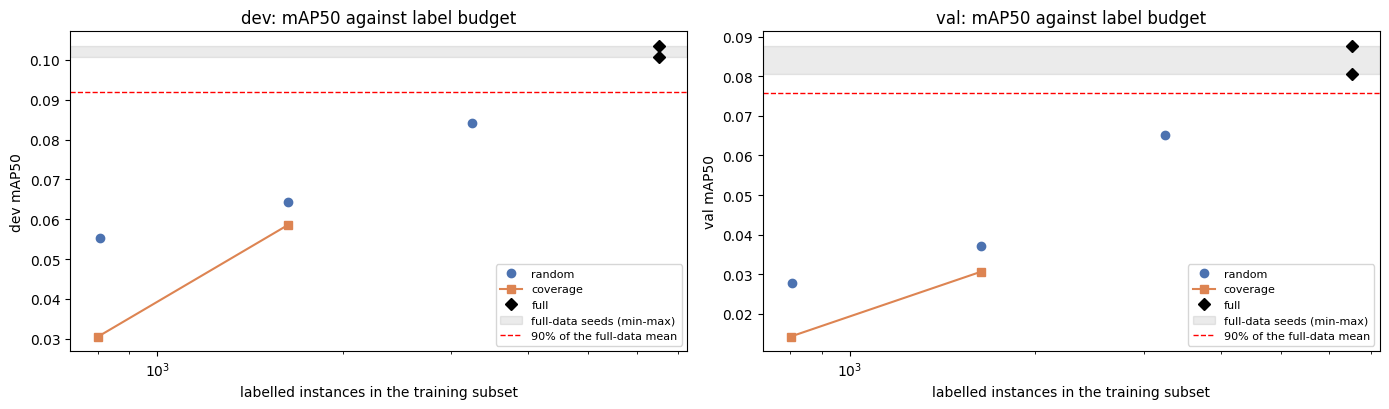

In [10]:
inst = COMPOSITION.instances
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for k, part in enumerate(("dev", "val")):
    t = TABLE[part]
    for kind, style in (("random", dict(c="#4c72b0", marker="o", ls="")), ("coverage", dict(c="#dd8452", marker="s", ls="-")),
                        ("full", dict(c="k", marker="D", ls=""))):
        arms = [a for a in AVAIL if ARMS.loc[a, "kind"] == kind]
        if arms:
            ax[k].plot(inst[arms], t.loc[arms, "mAP50"], label=kind, **style)
    if REF[part]["n"]:
        ax[k].axhspan(REF[part]["min"], REF[part]["max"], color="k", alpha=0.08, label="full-data seeds (min-max)")
        ax[k].axhline(REF[part]["threshold"], c="r", ls="--", lw=1, label="90% of the full-data mean")
    ax[k].set(xscale="log", xlabel="labelled instances in the training subset", ylabel=f"{part} mAP50", title=f"{part}: mAP50 against label budget")
    ax[k].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
fit_arms = [a for a in AVAIL if ARMS.loc[a, "kind"] in ("random", "full")]
fit_rows = []
for part in ("dev", "val"):
    for metric, col in (("mAP50", "mAP50"), ("class-agnostic AP50", "agnostic AP50")):
        if len(set(inst[fit_arms])) < 2:
            continue
        fit = log2_slope(inst[fit_arms].to_numpy(), TABLE[part].loc[fit_arms, col].to_numpy())
        gain = gain_for_extra_labels(fit["slope"], N_FULL, 500)
        fit_rows.append({"split": part, "metric": metric, "points": fit["n"], "slope per doubling": fit["slope"], "se": fit["se"],
                         "+500 labels": gain, "+500 as % of full score": 100 * gain / REF[part]["reference"]})
if fit_rows:
    display(pd.DataFrame(fit_rows).round(4))

# per class: dev AP50 of the class against the number of that class's instances in the subset (full data included)
cls_rows = []
for name, short in zip(NAMES, SHORT):
    n_c = np.array([COMPOSITION.loc[a, f"n {short}"] for a in fit_arms], float)
    ap = np.array([REPORT[(a, "dev")].per_class.set_index("class").AP50[name] for a in fit_arms], float)
    keep = (n_c > 0) & np.isfinite(ap)
    if len(set(n_c[keep])) < 2:
        continue
    fit = log2_slope(n_c[keep], ap[keep])
    n_full = float(COMPOSITION.loc[REFERENCE_ARMS[0], f"n {short}"])
    full_ap = np.nanmean([REPORT[(a, "dev")].per_class.set_index("class").AP50[name] for a in REF_ARMS])
    cls_rows.append({"class": short, "instances (full)": int(n_full), "AP50 dev (full)": full_ap, "slope per doubling": fit["slope"],
                     "se": fit["se"], "gain, +500 spread proportionally": fit["slope"] * np.log2(1 + 500 / N_FULL),
                     "gain, all +500 to this class (extrapolated)": gain_for_extra_labels(fit["slope"], n_full, 500)})
if cls_rows:
    display(pd.DataFrame(cls_rows).set_index("class").sort_values("slope per doubling", ascending=False).round(4))

,split,metric,points,slope per doubling,se,+500 labels,+500 as % of full score
0,dev,mAP50,5,0.016,0.001,0.002,1.693
1,dev,class-agnostic AP50,5,0.033,0.003,0.004,3.382
2,val,mAP50,5,0.020,0.002,0.002,2.511
3,val,class-agnostic AP50,5,0.051,0.003,0.005,6.381


,instances (full),AP50 dev (full),slope per doubling,se,"gain, +500 spread proportionally","gain, all +500 to this class (extrapolated)"
class,,,,,,
Box,2020,0.323,0.042,0.004,4.500e-03,0.013
Cargo,3240,0.115,0.016,0.002,1.700e-03,0.003
Flatbed,556,0.058,0.016,0.003,1.700e-03,0.015
Tractor,548,0.015,0.004,0.001,4.000e-04,0.004
Liquid,161,0.000,0.000,0.000,0.000e+00,0.000


## Stage 6 · What the surviving examples are

The composition of each subset (images, instances per class, images that contain the class, size mix) at every budget. The questions this stage has to answer from the numbers above
(fill in after the runs): does coverage keep the rare classes that random subsets lose; is its image count (scene diversity) or its class mix responsible for any difference; which classes lose most when the
budget shrinks; and whether a class with many instances but few distinct images (Tractor) behaves like a class with few instances.

In [12]:
for p in BUDGET:
    arms = [a for a in COMPOSITION.index if a.startswith((f"SR{p}_", f"SC{p}"))]
    if arms:
        print(f"budget {100 * BUDGET[p]:g}%")
        display(COMPOSITION.loc[arms, ["images", "instances", "median inst/image", "xs %"] + [f"n {s}" for s in SHORT] + [f"img {s}" for s in SHORT]].round(1))

budget 50%


,images,instances,median inst/image,xs %,n Cargo,n Box,n Flatbed,n Tractor,n Liquid,img Cargo,img Box,img Flatbed,img Tractor,img Liquid
arm,,,,,,,,,,,,,,
SR50_k0,198,3240,8.0,19.8,1523,1214,247,172,84,166,112,92,58,44
SC50,270,3209,4.0,22.9,1424,1025,310,347,103,208,153,113,62,60


budget 25%


,images,instances,median inst/image,xs %,n Cargo,n Box,n Flatbed,n Tractor,n Liquid,img Cargo,img Box,img Flatbed,img Tractor,img Liquid
arm,,,,,,,,,,,,,,
SR25_k0,102,1630,8.0,23.9,905,463,148,74,40,86,57,49,33,24
SC25,180,1629,3.0,23.9,701,534,169,157,68,120,93,76,52,41


budget 12.5%


,images,instances,median inst/image,xs %,n Cargo,n Box,n Flatbed,n Tractor,n Liquid,img Cargo,img Box,img Flatbed,img Tractor,img Liquid
arm,,,,,,,,,,,,,,
SR12_k0,54,806,8.0,27.2,460,209,85,34,18,45,30,25,16,11
SR12_k1,68,801,4.5,28.5,496,209,47,29,20,56,38,24,13,12
SC12,136,801,3.0,27.1,291,269,97,96,48,85,64,49,29,29


## Observations (fill in after the runs)

* **Reference:** full-data val and dev mAP50 over seeds 0 and 1 (mean, min, max), the 90% thresholds, and what the spread says about whether a 10% margin is resolvable.
* **Smallest tested subset that passes** (val and dev), its label budget as a share of train_core, its image count; the next smaller tested budget and its result. Not a proven minimum.
* **Random vs coverage** at each budget: difference against the random range and the paired intervals; per-class AP50 (is any gain in Flatbed/Tractor/Liquid?).
* **Curve shape (5.3):** slope per doubling overall and per class, +500 labels with its uncertainty; which classes benefit most and least; limited sample count versus label ambiguity (compare with the classification proxy's +0.04 per doubling).
* **Prediction check:** the two predictions declared in `exp.md` (detection saturates early vs the proxy's -13% at 50%) against what was observed.
* **Limits:** one training seed per subset arm, the fixed 50 epochs (fewer updates for small subsets), a 22-image val set, coverage deterministic and run once.